In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_image_folder = "/content/drive/MyDrive/ThesisDataset/Splits/train"
val_image_folder = "/content/drive/MyDrive/ThesisDataset/Splits/val"
test_image_folder = "/content/drive/MyDrive/ThesisDataset/Splits/test"

train_annotation_file = "/content/drive/MyDrive/ThesisDataset/Splits/train.json"
val_annotation_file = "/content/drive/MyDrive/ThesisDataset/Splits/val.json"
test_annotation_file = "/content/drive/MyDrive/ThesisDataset/Splits/test.json"

In [ ]:
import torchvision

In [ ]:
import os
import torch
import json
from PIL import Image

In [ ]:
import torch.nn.functional as F
from tqdm import tqdm

In [ ]:
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

In [ ]:
def get_num_classes_from_coco(json_file):
    with open(json_file, 'r') as f:
        data = json.load(f)

    categories = data.get('categories', [])

    if not categories:
        raise ValueError("No categories found in the provided COCO JSON file.")

    category_ids = [category['id'] for category in categories]

    category_info = {category['id']: category['name'] for category in categories}

    num_classes = len(categories) + 1

    category_names = [category['name'] for category in categories]

    return num_classes, category_info

num_classes, category_names = get_num_classes_from_coco(train_annotation_file)
print(f"Number of classes (including background): {num_classes}")
print(f"Category names: {category_names}")


Number of classes (including background): 8
Category names: {1: 'spider', 2: 'swiss_cheese', 5: 'crater', 12: 'BrightDune', 14: 'DarkDune', 16: 'Impact_Ejecta', 19: 'slope_streak'}


In [ ]:
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained = True)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth
100%|██████████| 160M/160M [00:01<00:00, 166MB/s]


In [ ]:
model

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [ ]:
import torch
import json
from PIL import Image
import torchvision.transforms as T

class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, json_file, image_dir, category_map=None):
        with open(json_file) as f:
            self.data = json.load(f)
        self.image_dir = image_dir

        self.indices = [img['id'] for img in self.data['images']]
        self.images = {img['id']: img['file_name'] for img in self.data['images']}

        self.annotations = {ann['image_id']: [] for ann in self.data['annotations']}

        if category_map is None:
            category_map = {
                1: 1,
                2: 2,
                5: 5,
                12: 3,
                14: 4,
                16: 6,
                19: 7
            }

        self.category_map = category_map

        for ann in self.data['annotations']:
            x, y, w, h = ann['bbox']
            x2, y2 = x + w, y + h
            mapped_category_id = self.category_map.get(ann['category_id'], ann['category_id'])
            self.annotations[ann['image_id']].append({
                'bbox': [x, y, x2, y2],
                'category_id': mapped_category_id
            })

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, indx):
        image_id = self.indices[indx]
        image_path = f"{self.image_dir}/{self.images[image_id]}"
        img = Image.open(image_path).convert('L')

        transform = T.Compose([
            T.ToTensor(),
            T.Normalize(mean=[0.5], std=[0.5])
        ])
        img = transform(img)

        annotations = self.annotations[image_id]

        boxes = [ann['bbox'] for ann in annotations]
        boxes_tensor = torch.tensor(boxes, dtype=torch.float32)

        labels = torch.tensor([ann['category_id'] for ann in annotations], dtype=torch.int64)

        target = {'boxes': boxes_tensor, 'labels': labels}

        return img, target

def coco_collate_fn(batch):
    return batch


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
device

device(type='cpu')

In [ ]:
train_loader = torch.utils.data.DataLoader(
    CustomDataset(json_file= train_annotation_file, image_dir= train_image_folder),
    batch_size=32,
    shuffle=True,
    collate_fn=coco_collate_fn,
    pin_memory= True if device.type == 'cuda' else False
)

In [ ]:
for batch in train_loader:
    images, targets = zip(*batch)
    print(f"Number of images in batch: {len(images)}")
    print(f"First image shape: {images[0].shape}")
    print(f"First target: {targets[0]}")
    break


Number of images in batch: 32
First image shape: torch.Size([1, 224, 224])
First target: {'boxes': tensor([[ 87.8238,   9.8678, 222.0264, 143.0837],
        [137.1630, 164.7930, 223.0132, 223.0132]]), 'labels': tensor([2, 2])}


In [ ]:
from torch.utils.data import DataLoader

val_loader = DataLoader(
    CustomDataset(json_file= val_annotation_file, image_dir= val_image_folder),
    batch_size=8,
    shuffle=True,
    collate_fn=coco_collate_fn,
    pin_memory=True if device.type == 'cuda' else False
)

In [ ]:
for batch in val_loader:
    images, targets = zip(*batch)
    print(f"Number of images in batch: {len(images)}")
    print(f"First image shape: {images[0].shape}")
    print(f"First target: {targets[0]}")
    break

Number of images in batch: 8
First image shape: torch.Size([1, 224, 224])
First target: {'boxes': tensor([[ 60.1938,  51.3128, 170.7137, 167.7533]]), 'labels': tensor([5])}


In [ ]:
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

In [ ]:
model

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [ ]:
print(f"Using device: {device}")
print(f"CUDA Available: {torch.cuda.is_available()}")

Using device: cpu
CUDA Available: False


In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0005
)

In [ ]:
epoches = 10

In [ ]:
best_model_wts = model.state_dict()
best_loss = float('inf')

In [ ]:
model = model.to(device)

In [ ]:
model_save_folder = '/content/drive/MyDrive/ThesisTraining'

if not os.path.exists(model_save_folder):
    os.makedirs(model_save_folder)


In [ ]:
checkpoint_path = "model_epoch_4.pth"

checkpoint = torch.load(checkpoint_path, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

In [ ]:
resume_epoch = checkpoint['epoch']
loss = checkpoint['loss']

In [ ]:
for epoch in range(resume_epoch, epoches):
    model.train()
    running_loss = 0.0
    print(f"Epoch {epoch + 1}/{epoches}")
    progress_bar = tqdm(train_loader, desc=f"Training", ncols=80)

    for batch in progress_bar:
        images, targets = zip(*batch)
        images = [image.to(device) for image in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        losses.backward()
        optimizer.step()

        running_loss += losses.item()
        progress_bar.set_postfix({
            "loss": f"{losses.item():.4f}"
        })

    avg_train_loss = running_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/{epoches} - Training Loss: {avg_train_loss:.4f}")

    model.eval()
    with torch.no_grad():
        running_iou_loss = 0.0
        total_batches = 0

        for batch in val_loader:
            try:
                images, targets = zip(*batch)
                images = [img.to(device) for img in images]
                targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

                outputs = model(images)
                iou_loss = 0.0
                for o, t in zip(outputs, targets):
                    if o["boxes"].size(0) == 0 or t["boxes"].size(0) == 0:
                        continue
                    min_size = min(o["boxes"].size(0), t["boxes"].size(0))
                    iou_loss += F.smooth_l1_loss(o["boxes"][:min_size], t["boxes"][:min_size])

                if len(outputs) > 0:
                    iou_loss /= len(outputs)
                    running_iou_loss += iou_loss.item()
                    total_batches += 1

            except RuntimeError as e:
                print(f"Error during validation on batch: {e}")
                continue

        if total_batches > 0:
            avg_iou_loss = running_iou_loss / total_batches
        else:
            avg_iou_loss = 0.0
        print(f"Epoch {epoch + 1}/{epoches} - Validation IoU Loss: {avg_iou_loss:.4f}")


    model_save_path = os.path.join(model_save_folder, f'model_epoch_{epoch + 1}.pth')

    torch.save({
        'epoch': epoch + 1,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': avg_train_loss,
    }, model_save_path)

print(f"Training Completed")

Epoch 5/10


Training: 100%|██████████████████| 56/56 [1:06:01<00:00, 70.74s/it, loss=0.1484]


Epoch 5/10 - Training Loss: 0.1614
Epoch 5/10 - Validation IoU Loss: 19.8120
Epoch 6/10


Training: 100%|██████████████████| 56/56 [1:06:33<00:00, 71.32s/it, loss=0.1804]


Epoch 6/10 - Training Loss: 0.1423
Epoch 6/10 - Validation IoU Loss: 21.3316
Epoch 7/10


Training: 100%|██████████████████| 56/56 [1:07:03<00:00, 71.85s/it, loss=0.1331]


... (3 outputs left out)

Training: 100%|██████████████████| 56/56 [1:06:52<00:00, 71.66s/it, loss=0.1365]


Epoch 9/10 - Training Loss: 0.1170
Epoch 9/10 - Validation IoU Loss: 20.6458
Epoch 10/10


Training: 100%|██████████████████| 56/56 [1:07:09<00:00, 71.96s/it, loss=0.1299]


Epoch 10/10 - Training Loss: 0.1149
Epoch 10/10 - Validation IoU Loss: 22.8675
Training Completed


In [ ]:
test_loader = torch.utils.data.DataLoader(
    CustomDataset(json_file= test_annotation_file, image_dir= test_image_folder),
    batch_size=32,
    shuffle=False,
    collate_fn=coco_collate_fn,
    pin_memory= True if device.type == 'cuda' else False
)

In [ ]:
for batch in test_loader:
    images, targets = zip(*batch)
    print(f"Number of images in batch: {len(images)}")
    print(f"First image shape: {images[0].shape}")
    print(f"First target: {targets[0]}")
    break

Number of images in batch: 32
First image shape: torch.Size([1, 224, 224])
First target: {'boxes': tensor([[ 63.1542,  97.6916, 159.8590, 119.4009],
        [ 48.3524, 110.5198, 146.0441, 132.2291],
        [ 59.2071, 190.4493, 193.4097, 217.0925]]), 'labels': tensor([7, 7, 7])}


In [ ]:
model_uploader = '/content/drive/MyDrive/ThesisTraining/model_epoch_10.pth'
checkpoint = torch.load(model_uploader, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device)
model.eval()

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [ ]:
import torchvision.ops as ops

confidence_threshold = 0.3

all_preds = []
all_targets = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating"):
        images, targets = zip(*batch)
        images = [img.to(device) for img in images]

        outputs = model(images)

        for output, target in zip(outputs, targets):
            high_conf_ts = output['scores'] >= confidence_threshold

            filtered_output = {
                'boxes' : output['boxes'][high_conf_ts].cpu(),
                'labels' : output['labels'][high_conf_ts].cpu(),
                'scores' : output['scores'][high_conf_ts].cpu()
            }
            if filtered_output['boxes'].size(0) > 0:
                all_preds.append(filtered_output)
            all_targets.append({
                'boxes': target['boxes'].cpu(),
                'labels': target['labels'].cpu()
            })

Evaluating: 100%|██████████| 16/16 [07:12<00:00, 27.02s/it]


In [ ]:
print(f"Length of predictions: {len(all_preds)}")
print(f"Length of targets: {len(all_targets)}")

Length of predictions: 509
Length of targets: 510


In [ ]:
print(f"First few predictions: {all_preds[:5]}")
print(f"First few targets: {all_targets[:5]}")


First few predictions: [{'boxes': tensor([[ 58.0237, 189.9306, 184.6250, 218.5660],
        [ 59.4520,  94.0981, 162.6122, 132.5946],
        [ 49.1857, 113.2505, 160.7642, 135.6625]]), 'labels': tensor([7, 7, 7]), 'scores': tensor([0.9945, 0.9897, 0.9166])}, {'boxes': tensor([[ 82.6104,  88.5590, 144.8091, 150.6359]]), 'labels': tensor([5]), 'scores': tensor([0.9873])}, {'boxes': tensor([[ 70.7018,  57.9615, 149.6250, 142.9852]]), 'labels': tensor([5]), 'scores': tensor([0.9647])}, {'boxes': tensor([[ 77.1226,  77.6405, 154.7455, 140.1440],
        [  0.0000, 104.9255,  27.6710, 179.7199]]), 'labels': tensor([3, 3]), 'scores': tensor([0.9913, 0.5264])}, {'boxes': tensor([[108.2116,  79.5008, 158.5474, 134.0507],
        [128.7705,  35.7077, 150.2912,  64.6658],
        [ 83.3832,  27.3223, 101.2968,  46.8637]]), 'labels': tensor([5, 5, 5]), 'scores': tensor([0.9920, 0.9592, 0.3101])}]
First few targets: [{'boxes': tensor([[ 63.1542,  97.6916, 159.8590, 119.4009],
        [ 48.3524, 11

In [ ]:
def calculate_iou(pred_boxes, gt_boxes):
    return ops.box_iou(pred_boxes, gt_boxes)

In [ ]:
import numpy as np
from scipy.optimize import linear_sum_assignment

def calculate_precision_recall(all_preds, all_targets, iou_threshold=0.5):
    precisions = []
    recalls = []

    for preds, targets in zip(all_preds, all_targets):
        if len(preds['boxes']) == 0 or len(targets['boxes']) == 0:
            continue

        ious = calculate_iou(preds['boxes'], targets['boxes']).cpu().numpy()

        row_ind, col_ind = linear_sum_assignment(-ious)
        matched_ious = ious[row_ind, col_ind]

        valid_matches = matched_ious > iou_threshold
        tp = valid_matches.sum()

        precisions.append(tp / len(preds['boxes']))
        recalls.append(tp / len(targets['boxes']))

    precision = np.mean(precisions) if precisions else 0.0
    recall = np.mean(recalls) if recalls else 0.0
    return precision, recall


In [ ]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
results = []

for thresh in thresholds:
    all_preds = []
    for output in outputs:
        high_conf_ts = output['scores'] >= thresh
        filtered_output = {
            'boxes': output['boxes'][high_conf_ts],
            'labels': output['labels'][high_conf_ts],
            'scores': output['scores'][high_conf_ts],
        }
        all_preds.append(filtered_output)

    precision, recall = calculate_precision_recall(all_preds, all_targets, iou_threshold=0.1)
    results.append((thresh, precision, recall))
    print(f"Threshold {thresh}: Precision {precision:.4f}, Recall {recall:.4f}")


Threshold 0.2: Precision 0.5182, Recall 0.6743
Threshold 0.3: Precision 0.5421, Recall 0.6631
Threshold 0.4: Precision 0.5716, Recall 0.6090
Threshold 0.5: Precision 0.5812, Recall 0.6090
Threshold 0.6: Precision 0.6234, Recall 0.6090
Threshold 0.7: Precision 0.6324, Recall 0.6090
Threshold 0.8: Precision 0.6557, Recall 0.6090


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix
from torchvision.ops import box_iou

def calculate_iou_matrix(pred_boxes, gt_boxes):
    """Calculate IoU matrix for predictions and ground truth."""
    return box_iou(pred_boxes, gt_boxes)

def calculate_confusion_matrix(all_preds, all_targets, iou_threshold=0.5):
    """Calculate confusion matrix based on predictions and ground truth."""
    pred_labels = []
    true_labels = []

    for preds, targets in zip(all_preds, all_targets):
        pred_boxes = preds['boxes']
        pred_classes = preds['labels']
        gt_boxes = targets['boxes']
        gt_classes = targets['labels']

        if pred_boxes.size(0) == 0 and gt_boxes.size(0) == 0:
            continue
        elif pred_boxes.size(0) == 0:
            true_labels.extend(gt_classes.tolist())
            pred_labels.extend([-1] * len(gt_classes))
            continue
        elif gt_boxes.size(0) == 0:
            pred_labels.extend(pred_classes.tolist())
            true_labels.extend([-1] * len(pred_classes))
            continue

        iou_matrix = calculate_iou_matrix(pred_boxes, gt_boxes)

        matched_pred_indices = iou_matrix.max(dim=1).indices
        matched_iou_values = iou_matrix.max(dim=1).values

        for i, pred_label in enumerate(pred_classes):
            if matched_iou_values[i] >= iou_threshold:
                gt_label = gt_classes[matched_pred_indices[i]].item()
                pred_labels.append(pred_label.item())
                true_labels.append(gt_label)
            else:
                pred_labels.append(pred_label.item())
                true_labels.append(-1)

        unmatched_gt_indices = torch.where(iou_matrix.max(dim=0).values < iou_threshold)[0]
        true_labels.extend(gt_classes[unmatched_gt_indices].tolist())
        pred_labels.extend([-1] * len(unmatched_gt_indices))

    unique_labels = np.unique(true_labels + pred_labels)
    return confusion_matrix(true_labels, pred_labels, labels=unique_labels)

conf_matrix = calculate_confusion_matrix(all_preds, all_targets, iou_threshold=0.05)
print("Confusion Matrix:\n", conf_matrix)

Confusion Matrix:
 [[ 0  0  0 14  8  0  4]
 [ 9  0  0  0  0  0  1]
 [ 4  0  0  1  0  1  4]
 [ 8  0  0  1  2  2  0]
 [ 4  0  1  0  1  1  0]
 [ 5  0  0  2  6  7  3]
 [ 3  0  0  4  0  3  0]]


In [ ]:
def calculate_iou_matrix(pred_boxes, gt_boxes):
    return ops.box_iou(pred_boxes, gt_boxes)

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, average_precision_score
from torchvision.ops import box_iou

def calculate_confusion_matrix(all_preds, all_targets, iou_threshold=0.5):
    pred_labels = []
    true_labels = []

    for preds, targets in zip(all_preds, all_targets):
        pred_boxes = preds['boxes']
        pred_classes = preds['labels']
        gt_boxes = targets['boxes']
        gt_classes = targets['labels']

        if pred_boxes.size(0) == 0 and gt_boxes.size(0) == 0:
            continue
        elif pred_boxes.size(0) == 0:
            true_labels.extend(gt_classes.tolist())
            pred_labels.extend([-1] * len(gt_classes))  # False negatives
            continue
        elif gt_boxes.size(0) == 0:
            pred_labels.extend(pred_classes.tolist())
            true_labels.extend([-1] * len(pred_classes))  # False positives
            continue

        iou_matrix = calculate_iou_matrix(pred_boxes, gt_boxes)

        matched_pred_indices = iou_matrix.max(dim=1).indices
        matched_iou_values = iou_matrix.max(dim=1).values

        for i, pred_label in enumerate(pred_classes):
            if matched_iou_values[i] >= iou_threshold:
                gt_label = gt_classes[matched_pred_indices[i]].item()
                pred_labels.append(pred_label.item())
                true_labels.append(gt_label)
            else:
                pred_labels.append(pred_label.item())
                true_labels.append(-1)

        unmatched_gt_indices = torch.where(iou_matrix.max(dim=0).values < iou_threshold)[0]
        true_labels.extend(gt_classes[unmatched_gt_indices].tolist())
        pred_labels.extend([-1] * len(unmatched_gt_indices))

    unique_labels = np.unique(true_labels + pred_labels)
    return confusion_matrix(true_labels, pred_labels, labels=unique_labels)

In [ ]:
def calculate_map(all_preds, all_targets, iou_threshold=0.5):
    ap_per_class = []

    for preds, targets in zip(all_preds, all_targets):
        pred_boxes = preds['boxes']
        pred_scores = preds['scores']
        pred_classes = preds['labels']
        gt_boxes = targets['boxes']
        gt_classes = targets['labels']

        if pred_boxes.size(0) == 0 or gt_boxes.size(0) == 0:
            continue

        iou_matrix = calculate_iou(pred_boxes, gt_boxes)
        for class_id in np.unique(pred_classes.cpu().numpy()):
            gt_class_mask = gt_classes == class_id
            pred_class_mask = pred_classes == class_id

            iou_thresholded = iou_matrix >= iou_threshold
            matched_pred_indices = iou_thresholded.sum(dim=1) > 0

            true_positives = matched_pred_indices.sum().item()
            false_positives = (pred_class_mask.sum() - true_positives)
            false_negatives = (gt_class_mask.sum() - true_positives)

            precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0
            recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0

            if pred_class_mask.sum() > 0:
                pred_scores_class = pred_scores[pred_class_mask].cpu().numpy().flatten()
                gt_class_mask = gt_class_mask.cpu().numpy().flatten()

                if len(pred_scores_class) > 0 and len(gt_class_mask) > 0:
                    try:
                        ap = average_precision_score(gt_class_mask, pred_scores_class)
                        ap_per_class.append(ap)
                    except ValueError:
                        continue

    return np.mean(ap_per_class) if ap_per_class else 0

mAP = calculate_map(all_preds, all_targets, iou_threshold=0.1)
print(f"Mean Average Precision (mAP): {mAP:.4f}")


Mean Average Precision (mAP): 0.4444


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


In [ ]:
print(f"Mean Average Precision (mAP): {mAP:.4f}")

Mean Average Precision (mAP): 0.4444


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_ranking.py:1030: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


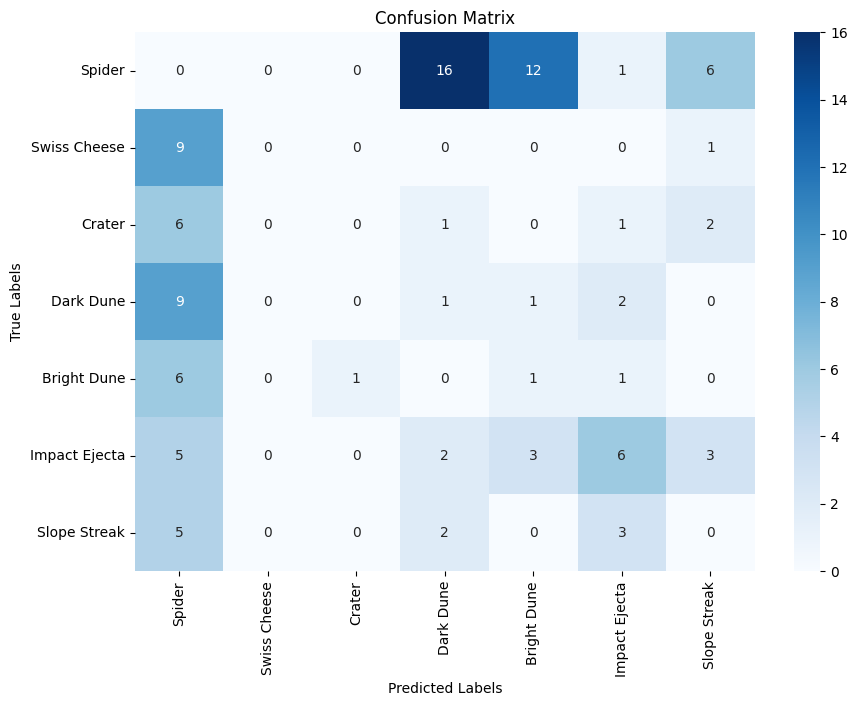

In [ ]:
def plot_confusion_matrix(conf_matrix, class_names):
    plt.figure(figsize=(10, 7))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.title("Confusion Matrix")
    plt.ylabel("True Labels")
    plt.xlabel("Predicted Labels")
    plt.show()

conf_matrix = calculate_confusion_matrix(all_preds, all_targets, iou_threshold=0.1)
mAP = calculate_map(all_preds, all_targets, iou_threshold=0.1)

class_names = ['Spider', 'Swiss Cheese', 'Crater', 'Dark Dune', 'Bright Dune', 'Impact Ejecta', 'Slope Streak']
plot_confusion_matrix(conf_matrix, class_names)
